# EDA для рекомендаций фильмов

Чекпойнт №2 · команда 129

Хотим рекомендовать фильмы по прошлым оценкам пользователей. Целевая переменная `rating` хранит оценку от 0,5 до 5. Будем считать, что фильм понравился при оценке 4 или выше.

## 1. Что в файлах

В `ratings` около 32 млн оценок, по одной на строку. В первой строке пользователь №1 поставил фильму №17 четыре звезды. По `movieId` в `movies` находим его название и жанры. В `tags` лежат метки от пользователей, в `links` записаны ID фильмов в IMDb и TMDB.

[MovieLens 32M](https://grouplens.org/datasets/movielens/32m/)

In [1]:
from math import ceil
from pathlib import Path
from shutil import copyfileobj
from tempfile import TemporaryDirectory
from urllib.request import urlopen
from zipfile import ZipFile, is_zipfile

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import ScalarFormatter

sns.set_theme(style="whitegrid")

archive = Path("ml-32m.zip")
if not is_zipfile(archive):
    print("Скачиваем MovieLens 32M (239 МБ).")
    url = "https://files.grouplens.org/datasets/movielens/ml-32m.zip"
    with TemporaryDirectory(dir=archive.parent) as temp_dir:
        downloaded = Path(temp_dir) / archive.name
        with urlopen(url, timeout=60) as response, downloaded.open("wb") as file:
            copyfileobj(response, file, 1024 * 1024)
        if not is_zipfile(downloaded):
            raise ValueError("Не удалось скачать ZIP-архив MovieLens.")
        downloaded.replace(archive)

with ZipFile(archive) as dataset:
    ratings = pd.read_csv(dataset.open("ml-32m/ratings.csv"), dtype={"rating": "float32"})
    movies = pd.read_csv(dataset.open("ml-32m/movies.csv"))
    tags = pd.read_csv(dataset.open("ml-32m/tags.csv"), keep_default_na=False, na_values=[""])
    links = pd.read_csv(dataset.open("ml-32m/links.csv"), dtype={"imdbId": str})

tables = {"ratings": ratings, "movies": movies, "tags": tags, "links": links}
for name, table in tables.items():
    print(name, table.shape)
    display(table.head(3))

ratings.info()

ratings (32000204, 4)


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976


movies (87585, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance


tags (2000072, 4)


,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469


links (87585, 3)


,movieId,imdbId,tmdbId
0,1,0114709,862.0
1,2,0113497,8844.0
2,3,0113228,15602.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float32
 3   timestamp  int64  
dtypes: float32(1), int64(3)
memory usage: 854.5 MB


В `describe` строка `50%` показывает медиану. Для текстовых столбцов `unique` даёт число разных значений, а `top` показывает самое частое. По минимуму и максимуму оценок можно проверить, укладываются ли они в шкалу.

In [2]:
for name, table in tables.items():
    print(name)
    display(table.describe(include="all").T)

ratings


,count,mean,std,min,25%,50%,75%,max
userId,32000204.0,1.002785e+05,5.794905e+04,1.0,5.005300e+04,1.002970e+05,1.504510e+05,2.009480e+05
movieId,32000204.0,2.931861e+04,5.095816e+04,1.0,1.233000e+03,3.452000e+03,4.419900e+04,2.927570e+05
rating,32000204.0,3.540396e+00,1.058986e+00,0.5,3.000000e+00,3.500000e+00,4.000000e+00,5.000000e+00
timestamp,32000204.0,1.275241e+09,2.561630e+08,789652004.0,1.051012e+09,1.272622e+09,1.503158e+09,1.697164e+09


movies


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
movieId,87585.0,NaN,NaN,NaN,157651.365519,79013.402099,1.0,112657.0,165741.0,213203.0,292757.0
title,87585,87382,Alone (2020),4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genres,87585,1798,Drama,12443,NaN,NaN,NaN,NaN,NaN,NaN,NaN


tags


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
userId,2000072.0,NaN,NaN,NaN,81928.586291,38106.498431,22.0,68413.0,78213.0,103698.0,162279.0
movieId,2000072.0,NaN,NaN,NaN,71893.261729,74803.79499,1.0,4011.0,52328.0,122294.0,292629.0
tag,2000072,140981,sci-fi,10996,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,2000072.0,NaN,NaN,NaN,1528913885.942506,129083512.886774,1135429210.0,1473614704.25,1574071062.0,1614739619.0,1697154983.0


links


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
movieId,87585.0,NaN,NaN,NaN,157651.365519,79013.402099,1.0,112657.0,165741.0,213203.0,292757.0
imdbId,87585,87585,0114709,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tmdbId,87461.0,NaN,NaN,NaN,241382.280422,247146.667043,2.0,46836.0,139272.0,381693.0,1186337.0


## 2. Пропуски и ошибки

Считаем пустые ячейки в каждом столбце. Для процента делим это число на количество строк в его таблице.

In [3]:
for name, table in tables.items():
    missing = table.isna().sum()
    print(name)
    display(pd.DataFrame({
        "пропусков": missing,
        "доля строк, %": (100 * missing / len(table)).round(4),
    }))
    print(f"Пустых ячеек во всей таблице: {100 * missing.sum() / table.size:.4f}%")

del tables

ratings


,пропусков,"доля строк, %"
userId,0,0.0
movieId,0,0.0
rating,0,0.0
timestamp,0,0.0


Пустых ячеек во всей таблице: 0.0000%
movies


,пропусков,"доля строк, %"
movieId,0,0.0
title,0,0.0
genres,0,0.0


Пустых ячеек во всей таблице: 0.0000%
tags


,пропусков,"доля строк, %"
userId,0,0.0
movieId,0,0.0
tag,0,0.0
timestamp,0,0.0


Пустых ячеек во всей таблице: 0.0000%
links


,пропусков,"доля строк, %"
movieId,0,0.0000
imdbId,0,0.0000
tmdbId,124,0.1416


Пустых ячеек во всей таблице: 0.0472%


### Какие значения считаем ошибкой

Оценка должна быть от 0,5 до 5 с шагом в ползвезды. Проверяем также, что номер пользователя положительный, фильм есть в каталоге, а время попадает в период с 1995 по 2023 год. Строки с ошибками убираем. Если один пользователь несколько раз оценил тот же фильм, оставляем последнюю по времени оценку.

In [4]:
scale = [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5]
start = pd.Timestamp("1995-01-01", tz="UTC").timestamp()
end = pd.Timestamp("2024-01-01", tz="UTC").timestamp()

good_score = ratings["rating"].isin(scale)
good_user = ratings["userId"] > 0
good_movie = ratings["movieId"].isin(movies["movieId"])
good_time = ratings["timestamp"].between(start, end, inclusive="left")
good_row = good_score & good_user & good_movie & good_time

print("Оценка вне шкалы:", (~good_score).sum())
print("Некорректный пользователь:", (~good_user).sum())
print("Фильм вне каталога:", (~good_movie).sum())
print("Некорректное время:", (~good_time).sum())
if not good_row.all():
    ratings = ratings.loc[good_row].copy()

pair = ["userId", "movieId"]
duplicates = ratings.duplicated(pair).sum()
print("Повторные пары пользователь — фильм:", duplicates)
if duplicates:
    ratings = ratings.sort_values("timestamp", kind="stable").drop_duplicates(pair, keep="last")

del good_score, good_user, good_movie, good_time, good_row

Оценка вне шкалы: 0
Некорректный пользователь: 0
Фильм вне каталога: 0
Некорректное время: 0


Повторные пары пользователь — фильм: 0


In [5]:
print("Повторные ID в movies:", movies["movieId"].duplicated().sum())
print("Повторные ID в links:", links["movieId"].duplicated().sum())
print("Ссылки без карточки:", (~links["movieId"].isin(movies["movieId"])).sum())

good_tag = (
    (tags["userId"] > 0)
    & tags["movieId"].isin(movies["movieId"])
    & tags["timestamp"].between(start, end, inclusive="left")
)
print("Теги с ошибкой в ID или времени:", (~good_tag).sum())
print("Точные повторы тегов:", tags.duplicated().sum())
tags = tags.loc[good_tag].drop_duplicates().copy()

good_imdb = links["imdbId"].str.fullmatch(r"0*[1-9][0-9]*", na=False)
print("Неверные IMDb ID:", (links["imdbId"].notna() & ~good_imdb).sum())
print("Неверные TMDB ID:", (links["tmdbId"] <= 0).sum())
links["imdbId"] = links["imdbId"].where(good_imdb)
links["tmdbId"] = links["tmdbId"].where(links["tmdbId"] > 0)

Повторные ID в movies: 0
Повторные ID в links: 0
Ссылки без карточки: 0
Теги с ошибкой в ID или времени: 0


Точные повторы тегов: 0


Неверные IMDb ID: 0
Неверные TMDB ID: 0


### Пропуски, которые спрятаны в тексте

Запись `(no genres listed)` заменяем на «Не указан». Год берём из скобок в конце названия. Например, из `Toy Story (1995)` получаем 1995. Если подходящего года или внешнего ID нет, оставляем пропуск.

У тегов убираем пробелы по краям. Тег из одних пробелов после этого тоже считаем пустым.

In [6]:
movies["genres"] = movies["genres"].replace("(no genres listed)", "Не указан").fillna("Не указан")
year = movies["title"].str.extract(r"\((\d{4})\)\s*\)*\s*$", expand=False).astype(float)
movies["year"] = year.where(year.between(1870, 2023))
tags["tag"] = tags["tag"].str.strip().replace("", pd.NA)

hidden_missing = pd.DataFrame({
    "пропусков": [
        movies["genres"].eq("Не указан").sum(),
        movies["year"].isna().sum(),
        links["tmdbId"].isna().sum(),
        tags["tag"].isna().sum(),
    ],
    "строк": [len(movies), len(movies), len(links), len(tags)],
}, index=["жанр", "год выпуска", "TMDB ID", "текст тега"])
hidden_missing["доля, %"] = 100 * hidden_missing["пропусков"] / hidden_missing["строк"]
display(hidden_missing.round(4))

,пропусков,строк,"доля, %"
жанр,7080,87585,8.0836
год выпуска,616,87585,0.7033
TMDB ID,124,87585,0.1416
текст тега,6,2000072,0.0003


Проверили шкалу оценок, ID и даты. Ошибок и повторных пар в оценках не нашли. Жанр отсутствует у 7 080 фильмов, это самый частый пропуск в карточках (около 8% каталога).

## 3. Как ставят оценки

На шкале десять возможных значений. Посчитаем, сколько раз встречается каждое.

,количество
rating,
0.5,525132
1.0,946675
1.5,531063
2.0,2028622
2.5,1685386
3.0,6054990
3.5,4290105
4.0,8367654
4.5,2974000


Средняя оценка: 3.54
Доля оценок от 4: 49.8%


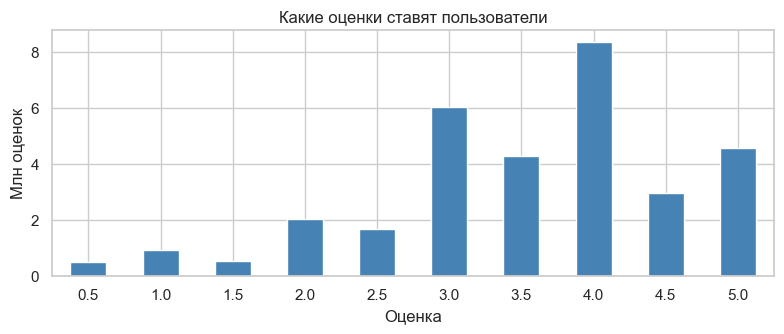

In [7]:
score_counts = ratings["rating"].value_counts().sort_index()
display(score_counts.to_frame("количество"))
print(f"Средняя оценка: {ratings['rating'].mean():.2f}")
print(f"Доля оценок от 4: {(ratings['rating'] >= 4).mean():.1%}")

(score_counts / 1_000_000).plot.bar(color="steelblue", figsize=(8, 3.5), rot=0)
plt.title("Какие оценки ставят пользователи")
plt.xlabel("Оценка")
plt.ylabel("Млн оценок")
plt.tight_layout()
plt.show()

Чаще всего ставили 4. Четвёрки и более высокие оценки составили 49,8%.

### Сколько оценок у фильма

Для каждого фильма считаем число оценок, их среднюю и число непустых тегов. Если оценок нет, в счётчике будет 0, а средняя останется пустой.

In [8]:
user_counts = ratings["userId"].value_counts()
movie_scores = ratings.groupby("movieId")["rating"].agg(["size", "mean"])
tag_counts = tags.groupby("movieId")["tag"].count()

movies["n_ratings"] = movies["movieId"].map(movie_scores["size"]).fillna(0).astype(int)
movies["mean_rating"] = movies["movieId"].map(movie_scores["mean"])
movies["n_tags"] = movies["movieId"].map(tag_counts).fillna(0).astype(int)

possible_pairs = len(user_counts) * len(movies)
density = len(ratings) / possible_pairs
print("Пользователей с оценками:", len(user_counts))
print("Фильмов без оценок:", (movies["n_ratings"] == 0).sum())
print(f"Пар пользователь — фильм с оценкой: {density:.4%}")
print(f"Пар без оценки: {1 - density:.4%}")

top_n = ceil(len(movie_scores) * 0.01)
top_ratings = movies["n_ratings"].nlargest(top_n).sum()
print(f"На {top_n} самых оцениваемых фильмов приходится {top_ratings / len(ratings):.2%} оценок")
print("Фильмов с 1–4 оценками:", movies["n_ratings"].between(1, 4).sum())

Пользователей с оценками: 200948
Фильмов без оценок: 3153
Пар пользователь — фильм с оценкой: 0.1818%
Пар без оценки: 99.8182%
На 845 самых оцениваемых фильмов приходится 54.88% оценок
Фильмов с 1–4 оценками: 40548


Оценка есть лишь для 0,18% пар «пользователь, фильм». Для остальных пар значение неизвестно. Подстановка нулей исказила бы средние.

На диаграмме размаха линия внутри ящика показывает медиану, точки за усами отмечают крайние значения. Шкалу сжали, чтобы на ней поместились и маленькие числа, и десятки тысяч оценок.

Оценки на пользователя. Медиана: 73, максимум: 33332
Оценки на фильм. Медиана: 5, максимум: 102929


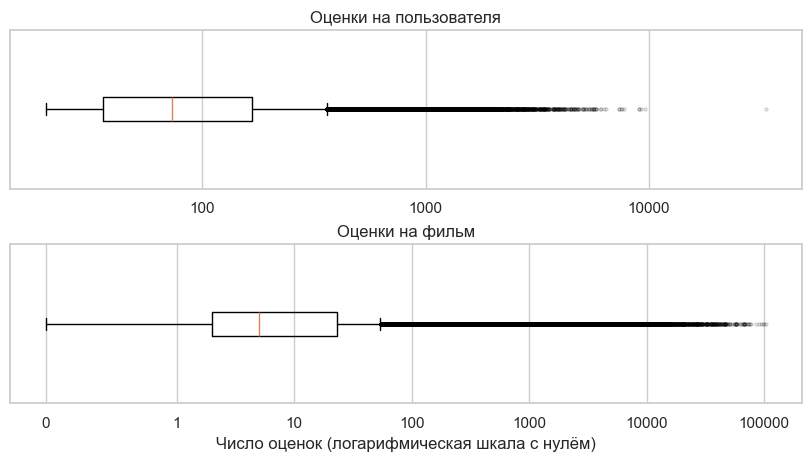

,title,n_ratings,mean_rating
314,"Shawshank Redemption, The (1994)",102929,4.40
351,Forrest Gump (1994),100296,4.05
292,Pulp Fiction (1994),98409,4.20
2480,"Matrix, The (1999)",93808,4.16
585,"Silence of the Lambs, The (1991)",90330,4.15


In [9]:
fig, axes = plt.subplots(2, 1, figsize=(8, 4.5), layout="constrained")
counts = {"Оценки на пользователя": user_counts, "Оценки на фильм": movies["n_ratings"]}
for ax, (name, values) in zip(axes, counts.items()):
    print(f"{name}. Медиана: {values.median():.0f}, максимум: {values.max()}")
    ax.boxplot(values, orientation="horizontal", flierprops={"markersize": 2, "alpha": 0.2})
    ax.set_xscale("symlog", linthresh=1)
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.set_title(name)
    ax.set_yticks([])

axes[1].set_xlabel("Число оценок (логарифмическая шкала с нулём)")
plt.show()
display(movies.nlargest(5, "n_ratings")[["title", "n_ratings", "mean_rating"]].round(2))

Медиана составляет 5 оценок на фильм. У «Побега из Шоушенка» их 102 929. Такой счётчик правдоподобен для популярного фильма, поэтому большие значения оставляем.

### Оценки и пропуски в карточках

Проверим, ниже ли медиана числа оценок у фильмов с пропусками в карточках.

In [10]:
missing_fields = {
    "Жанр": movies["genres"].eq("Не указан"),
    "Год": movies["year"].isna(),
    "TMDB ID": ~movies["movieId"].isin(links.loc[links["tmdbId"].notna(), "movieId"]),
}
for name, is_missing in missing_fields.items():
    print(name)
    status = is_missing.map({True: "пропуск", False: "заполнено"})
    display(movies.groupby(status)["n_ratings"].agg(["size", "median"]))

Жанр


,size,median
genres,,
заполнено,80505,5.0
пропуск,7080,2.0


Год


,size,median
year,,
заполнено,86969,5.0
пропуск,616,2.0


TMDB ID


,size,median
movieId,,
заполнено,87461,5.0
пропуск,124,3.0


У фильмов без жанра медиана составляет 2 оценки, у фильмов с жанром она равна 5. Для года выпуска получились те же числа. Фильмов без TMDB ID всего 124, у них медиана равна 3.

## 4. С чем связана оценка

### Оценки по годам

Из `timestamp` получаем год, когда поставили оценку. По каждому году считаем число оценок и средний балл. В 2023 году выгрузка заканчивается в октябре.

,size,mean
timestamp,,
2018,1391057,3.57
2019,1385467,3.58
2020,1688159,3.60
2021,1239912,3.58
2022,913105,3.50
2023,794054,3.57


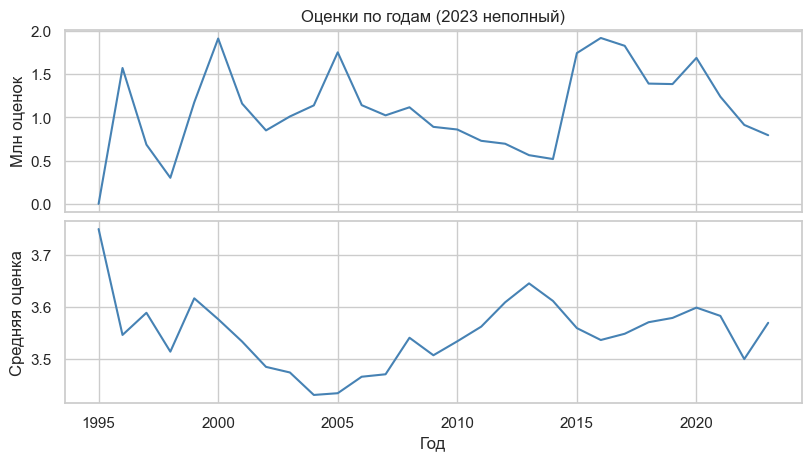

In [11]:
rating_year = pd.to_datetime(ratings["timestamp"], unit="s", utc=True).dt.year
by_year = ratings["rating"].groupby(rating_year).agg(["size", "mean"])
display(by_year.tail(6).round(2))

fig, axes = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True, layout="constrained")
(by_year["size"] / 1_000_000).plot(ax=axes[0], color="steelblue")
by_year["mean"].plot(ax=axes[1], color="steelblue")
axes[0].set_ylabel("Млн оценок")
axes[0].set_title("Оценки по годам (2023 неполный)")
axes[1].set_ylabel("Средняя оценка")
axes[1].set_xlabel("Год")
plt.show()

В 2021 году было 1,24 млн оценок, в 2022 году их стало 0,91 млн. Средний балл за это время снизился с 3,58 до 3,50.

### Жанр, год фильма и теги

Для каждого жанра берём фильмы с оценками и усредняем их средние баллы. Если у фильма два жанра, он входит в обе группы. `IMAX` оставляем отдельной меткой из файла. По `count` видно, сколько фильмов вошло в среднюю.

,count,mean
genres,,
Horror,8468,2.55
Sci-Fi,4797,2.70
Action,9296,2.84
Thriller,11555,2.84
Western,1489,2.91
Children,4447,2.92
Adventure,5156,2.94
Mystery,3894,2.94
Fantasy,3784,2.94


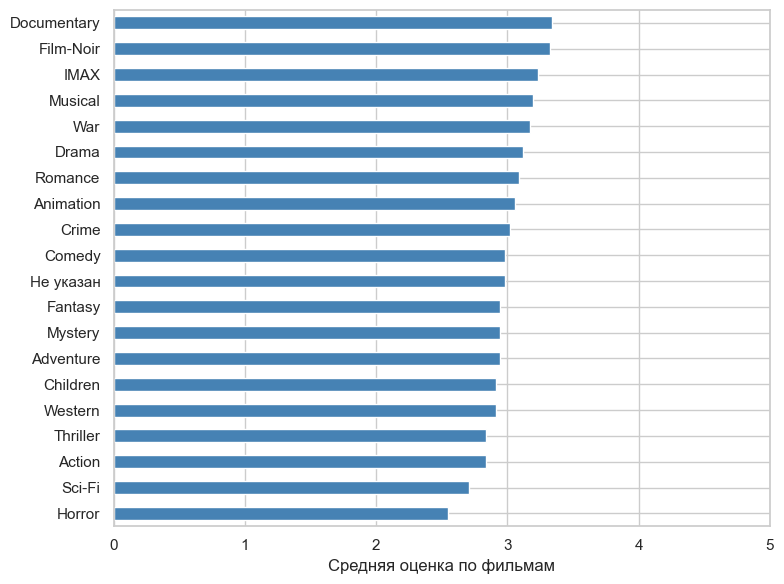

In [12]:
genres = movies[["genres", "mean_rating"]].copy()
genres["genres"] = genres["genres"].str.split("|")
genres = genres.explode("genres")
by_genre = genres.groupby("genres")["mean_rating"].agg(["count", "mean"]).sort_values("mean")
display(by_genre.round(2))

by_genre["mean"].plot.barh(figsize=(8, 6), color="steelblue", xlim=(0, 5))
plt.xlabel("Средняя оценка по фильмам")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [13]:
movies["decade"] = (movies["year"] // 10 * 10).astype("Int64")
print("По десятилетиям выпуска")
display(movies.groupby("decade", dropna=False)["mean_rating"].agg(["count", "mean"]).round(2))

print("Фильмов с тегами:", (movies["n_tags"] > 0).sum())
print("Частые теги")
display(tags["tag"].str.lower().value_counts().head(5))
print("Средняя оценка по фильмам с тегами и без")
has_tags = (movies["n_tags"] > 0).rename("есть теги")
display(movies.groupby(has_tags)["mean_rating"].agg(["count", "mean"]).round(2))

По десятилетиям выпуска


,count,mean
decade,,
1870,3,3.44
1880,13,2.92
1890,201,2.78
1900,298,3.12
1910,385,2.79
1920,699,3.09
1930,2272,2.98
1940,2446,3.07
1950,3243,3.07


Фильмов с тегами: 51323
Частые теги


tag
sci-fi         11457
atmospheric    10088
action          9344
comedy          9275
funny           8088
Name: count, dtype: int64

Средняя оценка по фильмам с тегами и без


,count,mean
есть теги,,
False,36262,2.91
True,48170,3.07


У документальных фильмов средняя оценка 3,34, у фильмов ужасов 2,55. Фильмы с тегами получили в среднем 3,07, а без тегов 2,91. Группы по десятилетиям сильно различаются по размеру. Например, из 1870-х есть только три фильма с оценками.

### Корреляции оценок

Для тепловой карты взяли 2 500 случайных оценок. У двух строк не было года выпуска, поэтому в расчёт вошло 2 498.

In [14]:
sample = ratings.sample(2_500, random_state=42).copy()
sample["Год фильма"] = sample["movieId"].map(movies.set_index("movieId")["year"])
sample["Год оценки"] = rating_year.loc[sample.index]
sample["Оценок\nу фильма"] = sample["movieId"].map(movie_scores["size"])
sample["Оценок\nу пользователя"] = sample["userId"].map(user_counts)
sample["Оценка"] = sample["rating"]

columns = ["Год фильма", "Год оценки", "Оценок\nу фильма", "Оценок\nу пользователя", "Оценка"]
pairs = sample[columns].dropna()
print("Строк для корреляций:", len(pairs))

Строк для корреляций: 2498


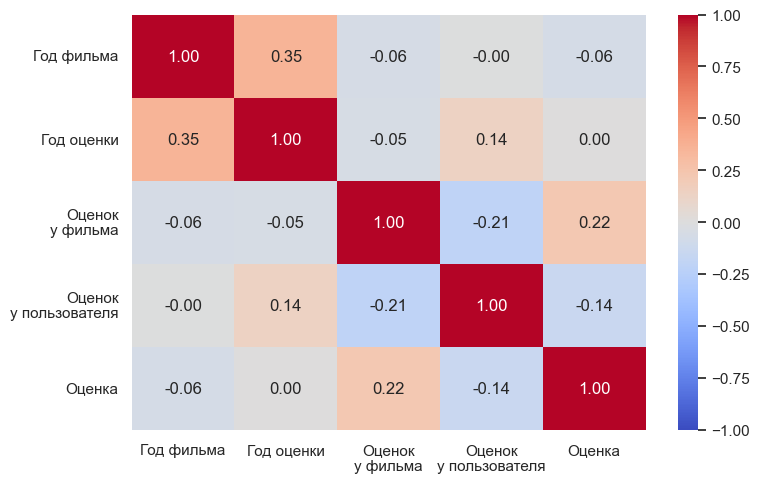

In [15]:
corr = pairs.corr()
plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

На тепловой карте числа около нуля означают слабую линейную связь. Балл немного выше у фильмов с большим числом оценок (0,22). Связь с годом выпуска слабее (−0,06), а с годом оценки почти нулевая.

## 5. Выводы

На 1% самых популярных фильмов приходится примерно 55% всех оценок. Сначала составим простой список популярных фильмов. Потом сравним с ним рекомендации будущей модели.

Почти у половины фильмов с оценками их всего от одной до четырёх. Средний балл по одной оценке может сильно измениться после второй, поэтому будем смотреть и на балл, и на число оценок. Если оценок мало, попробуем учитывать жанр.

Для проверки модели отложим более поздние оценки. Популярность и средний балл посчитаем по более ранним, чтобы модель заранее не видела оценки, по которым её проверяем.